# 🎯 Sübut Çəkisi (Weight of Evidence - WOE) və İnformasiya Dəyəri (Information Value - IV) ilə Logistik Reqressiya (Scorecard Modelləşdirməsi)
### 📊 Bank Müştərilərinin İtirilmə Riskinin (Customer Churn) Qiymətləndirilməsi və Kredit Skorinqi Metodologiyası

---

### 💡 WOE (Weight of Evidence) və IV (Information Value) Nədir?
**WOE (Weight of Evidence - Sübut Çəkisi)** və **IV (Information Value - İnformasiya Dəyəri)** qlobal bank və maliyyə sektorunda (xüsusən **Credit Scoring**, **Kredit Risklərinin Qiymətləndirilməsi - Basel II/III**, fırıldaqçılığın aşkarlanması və müştəri itkisi / **Churn** proqnozlaşdırılmasında) tətbiq olunan ən qabaqcıl ekonometrik data transformasiyası və əlamət mühəndisliyi (**Feature Engineering**) metodologiyasıdır.

Klassik maşın öyrənməsi modellərində ədədi sütunlar üçün standartlaşdırma (`StandardScaler`), kateqorik sütunlar üçün isə `One-Hot Encoding` istifadə olunur. Lakin maliyyə və risk modellərində bu ənənəvi yanaşmalar bir sıra ciddi problemlər yaradır:
1. **Ölçülülük Lənəti (Curse of Dimensionality)**: Yüksək sayda kateqoriyaya malik sütunlar yüzlərlə yeni binar sütun yaradır və modeli qeyri-sabit edir.
2. **Qeyri-Xətti Asılılıqlar**: Xətti reqressiya və klassik logistik reqressiya yaş, balans və ya gəlir kimi faktorların hədəflə yalnız düzxətli asılılıqda olduğunu fərz edir. Halbuki risk çox vaxt U-şəkilli və ya qeyri-monoton xarakter daşıyır (məsələn, həm çox gənclər, həm də çox yaşlılar daha çox getməyə meyillidir).
3. **Kənarlaşmalar (Outliers) və Boşluqlar (Missing Values)**: Bank verilənlərində anomaliyalar və boşluqlar modellərin dəqiqliyini kəskin zəiflədir.

---

### 📐 Riyazi Mexanizm və Düsturlar

#### 1️⃣ Qruplaşdırma (Binning):
Hər bir müstəqil əlamət ($X$) statistik olaraq mənalı və monoton risk qruplarına (**Bins**) bölünür. Hər qrupda:
- $\text{Total Good}$: Model üzrə hədəfi $0$ olan (məsələn, bankda qalan loyal müştərilər) ümumi sayı.
- $\text{Total Bad}$: Model üzrə hədəfi $1$ olan (məsələn, bankı tərk edən / churn müştərilər) ümumi sayı.
- $\text{Good}_i$: Həmin $i$-ci qrupdakı loyal müştərilərin sayı.
- $\text{Bad}_i$: Həmin $i$-ci qrupdakı getmiş müştərilərin sayı.

Paylanma nisbətləri hesablanır:
$$\% \text{ Good}_i = \frac{\text{Good}_i}{\text{Total Good}}, \qquad \% \text{ Bad}_i = \frac{\text{Bad}_i}{\text{Total Bad}}$$

#### 2️⃣ Sübut Çəkisi (Weight of Evidence - WOE):
Hər bir qrup üçün sübut çəkisi belə hesablanır:
$$\text{WOE}_i = \ln\left(\frac{\% \text{ Bad}_i}{\% \text{ Good}_i}\right)$$
*(Bəzi ədəbiyyatlarda $\ln(\% \text{Good} / \% \text{Bad})$ götürülür; `scorecardpy` kitabxanasında standart olaraq $\ln(\% \text{Bad} / \% \text{Good})$ düsturundan istifadə edilir).*

- **$\text{WOE}_i > 0$**: Həmin qrupda getmə riski ($\% \text{ Bad}$) qalmama nisbətindən yüksəkdir (Yüksək risk qrupu).
- **$\text{WOE}_i < 0$**: Həmin qrupda getmə riski ümumi ortalamadan aşağıdır (Təhlükəsiz qrup).
- **$\text{WOE}_i = 0$**: Qrupdakı risk ümumi portfelin orta riski ilə eynidir.

#### 3️⃣ İnformasiya Dəyəri (Information Value - IV):
Bütün qruplar üzrə cəmlənərək əlamətin hədəf dəyişəni ayırd etmə gücünü ölçür:
$$\text{IV} = \sum_{i=1}^{k} \left(\% \text{ Bad}_i - \% \text{ Good}_i\right) \times \text{WOE}_i$$

#### 📊 IV Dəyərinin İqtisadi Qiymətləndirmə Şkalası (Siddiqi, 2006):
| IV Dəyəri | Proqnozlaşdırma Gücü (Predictive Power) | Qərar |
| :--- | :--- | :--- |
| **$< 0.02$** | **Faydasız (Useless)** | Modeldən çıxarılmalıdır (heç bir ayırdetmə gücü yoxdur). |
| **$0.02 \le \text{IV} < 0.10$** | **Zəif (Weak)** | Yalnız digər dəyişənlərlə birlikdə zəif töhfə verə bilər. |
| **$0.10 \le \text{IV} < 0.30$** | **Orta (Medium)** | Yaxşı proqnoz gücünə malikdir, modelə daxil edilməlidir. |
| **$0.30 \le \text{IV} < 0.50$** | **Güclü (Strong)** | Çox yüksək ayırdetmə qabiliyyətinə malik əsas faktor. |
| **$\ge 0.50$** | **Şübhəli dərəcədə yüksək (Suspicious)** | Datanın gələcəkdən sızması (**Data Leakage**) riski ola bilər, yoxlanmalıdır. |

---

### 🌟 WOE Transformasiyasının 5 Böyük Üstünlüyü:
1. **Qeyri-Xətti Əlaqələri Xəttiləşdirir**: WOE log-odds şkalasında olduğu üçün logistik reqressiya ilə mükəmməl xətti uzlaşır.
2. **Kənarlaşmaları (Outliers) Avtomatik Zərərsizləşdirir**: Ədədlər aralıqlara bölündüyü üçün nəhəng dəyərlər ayrıca bir bin-ə düşür və reqressiyanı dağıda bilmir.
3. **Boşluqları (Missing Values) Təbii Emal Edir**: NaN dəyərlər üçün xüsusi bir bin (`missing`) yaradılır və bərpa etməyə (imputation) ehtiyac qalmır.
4. **Vahid Şkala**: Həm yaş (ədədi), həm də peşə (kateqorik) eyni WOE vahidinə çevrilir.
5. **Əmsalların İntuitivliyi**: WOE ilə çevrilmiş logistik modeldə bütün $\beta$ əmsalları təbii olaraq **$\approx 1.0$** ətrafında formalaşır.

---

### 🗺️ Layihənin Yol Xəritəsi (End-to-End Pipeline)
1. 📦 **Kitabxanaların İdxalı və Datanın Yüklənməsi**: 45,211 müştərinin bank göstəriciləri (`churn.csv`).
2. 🧹 **Məlumatın Təmizlənməsi**: Hədəf dəyişənin riyazi formata salınması.
3. 📊 **İnformasiya Dəyərinin (IV) Hesablanması**: Yalnız $\text{IV} \ge 0.02$ olan əhəmiyyətli faktorların seçilməsi.
4. ✂️ **Datanın Bölünməsi (Train / Test Split)**: Binning qaydalarının yalnız `train` üzərində öyrənilməsi.
5. 🔲 **WOE Qruplaşdırılması (Binning) və Çevirmə**: `scorecardpy` ilə `woebin` və `woebin_ply`.
6. 🔗 **Multikollinearite və VIF**: Korrelyasiyalı WOE əlamətlərinin aradan qaldırılması ($VIF < 2$).
7. 🔬 **GLM Binomial (Logistik Reqressiya) Modeli**: $\beta$ əmsalları, $z$-statistika və Odds Ratio ($e^\beta$) analizi.
8. 🎯 **Stepwise Backward Elimination**: Statistik baxımdan əhəmiyyətsiz ($p \ge 0.05$) faktorların ardıcıl çıxarılması.
9. 🔮 **Test Dəsti Üzərində Proqnozlar**: Hər müştəri üçün $P(y=1)$ getmə ehtimallarının hesablanması.
10. 🎯 **Optimal Qərar Həddinin (Threshold) Seçilməsi**: Train dəstində F1-score əsaslı optimal qərar həddi.
11. 📏 **Performansın Qiymətləndirilməsi**: Confusion Matrix, Precision, Recall, F1-Score və ROC-AUC.
12. ⚖️ **Overfitting və Underfitting Diaqnostikası**: Train vs Test müqayisəsi.
13. 📋 **Bank Risk Menecmenti üçün Yekun Nəticələr və Scorecard Tövsiyələri**.

## 📦 1. Tələb Olunan Kitabxanaların İdxalı (Importing Libraries)

In [1]:
import numpy as np
import pandas as pd

# Credit Scoring və WOE analizi üçün ixtisaslaşmış kitabxana
import scorecardpy as sc

# Xətti asılılıq (VIF) və modelin bölünməsi
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Klassifikasiya qiymətləndirmə metrikaları
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_curve, roc_auc_score, classification_report
)

# Statsmodels: GLM Binomial (Logistik Reqressiya) və statistik ekonometrik analiz
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Vizualizasiya alətləri
import seaborn as sns
import matplotlib.pyplot as plt

c:\Users\tarlan.cabiyev\AppData\Local\anaconda3\envs\ayna\lib\site-packages\scorecardpy\germancredit.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## 📂 2. Məlumat Dəstinin Yüklənməsi və Təmizlənməsi (Data Loading & Cleaning)

Bank müştərilərinin məlumat dəstini (`churn.csv`) yükləyirik.
- **Hədəf Dəyişən (`y`)**:
  - `yes` $\rightarrow 1$ (Müştəri getdi / Churn).
  - `no` $\rightarrow 0$ (Müştəri qaldı / Loyal).
- Hədəf dəyişəni mütləq **ədədi binar (`int`)** formatda saxlayırıq ki, `statsmodels` tənliyi standart $P(y=1)$ üzərindən qursun.
- Müşahidələri unikal eyniləşdirən `id` sütununu kənarlaşdırırıq.

In [2]:
data = pd.read_csv('churn.csv')
print('Məlumat dəstinin ölçüsü (Sətir, Sütun):', data.shape)
data.head()

Məlumat dəstinin ölçüsü (Sətir, Sütun): (45211, 18)


,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,1,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,2,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,3,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,4,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,5,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         45211 non-null  int64 
 1   age        45211 non-null  int64 
 2   job        45211 non-null  object
 3   marital    45211 non-null  object
 4   education  45211 non-null  object
 5   default    45211 non-null  object
 6   balance    45211 non-null  int64 
 7   housing    45211 non-null  object
 8   loan       45211 non-null  object
 9   contact    45211 non-null  object
 10  day        45211 non-null  int64 
 11  month      45211 non-null  object
 12  duration   45211 non-null  int64 
 13  campaign   45211 non-null  int64 
 14  pdays      45211 non-null  int64 
 15  previous   45211 non-null  int64 
 16  poutcome   45211 non-null  object
 17  y          45211 non-null  object
dtypes: int64(8), object(10)
memory usage: 6.2+ MB


In [3]:
# Hədəf dəyişənin ədədi binar formata (1 və 0) çevrilməsi
data["y"] = data["y"].replace({"yes": 1, "no": 0}).astype(int)

# Siniflərin paylanması (Faiz nisbəti)
print("Siniflərin paylanma nisbəti:")
print(data["y"].value_counts(normalize=True).round(4))

Siniflərin paylanma nisbəti:
y
0    0.883
1    0.117
Name: proportion, dtype: float64


In [4]:
# Sütunlar üzrə boşluqların (Missing Values) yoxlanması
na_df = data.isna().sum().reset_index().rename(columns={'index': 'col_name', 0: 'na_count'})
na_df = na_df.sort_values('na_count', ascending=False).reset_index(drop=True)
na_df

,col_name,na_count
0,id,0
1,age,0
2,poutcome,0
3,previous,0
4,pdays,0
5,campaign,0
6,duration,0
7,month,0
8,day,0
9,contact,0


In [5]:
target = "y"
exclude = ["id"]

# 'id' sütununu kənarlaşdırırıq
df_use = data.drop(columns=exclude, errors="ignore")
print('Analiz üçün istifadə olunacaq cədvəlin ölçüsü:', df_use.shape)

Analiz üçün istifadə olunacaq cədvəlin ölçüsü: (45211, 17)


## 📊 3. İnformasiya Dəyərinin (Information Value - IV) Hesablanması və Əlamət Seçimi

Bank risk modellərində lazımsız, səs-küy yaradan və proqnoz gücü olmayan əlamətləri dərhal kənarlaşdırmaq üçün **İnformasiya Dəyəri (IV)** hesablanır:
$$\text{IV} = \sum_{i=1}^{k} \left(\% \text{ Bad}_i - \% \text{ Good}_i\right) \times \text{WOE}_i$$

Beynəlxalq standartlara əsasən **$\text{IV} < 0.02$** olan əlamətlər proqnoz qabiliyyətinə malik deyil (**Useless**) və modeldən çıxarılmalıdır. Biz yalnız $\text{IV} \ge 0.02$ olan güclü faktorları saxlayırıq.

In [6]:
# scorecardpy vasitəsilə bütün əlamətlərin IV dəyərlərinin hesablanması
iv = sc.iv(df_use, y=target)
iv["info_value"] = iv["info_value"].round(4)
iv = iv.sort_values("info_value", ascending=False).reset_index(drop=True)
iv

,variable,info_value
0,duration,1.6672
1,balance,0.9050
2,pdays,0.5506
3,poutcome,0.5146
4,month,0.4361
5,contact,0.3004
6,previous,0.2317
7,age,0.2265
8,housing,0.1887
9,job,0.1557


In [7]:
# IV dəyəri 0.02-dən böyük olan (əhəmiyyətli) əlamətlərin seçilməsi
ivars = iv.loc[iv["info_value"] >= 0.02, "variable"].tolist()
print(f'Seçilmiş əhəmiyyətli əlamətlərin sayı (IV >= 0.02): {len(ivars)}')
print('Seçilmiş əlamətlər:\n', ivars)

df_iv = df_use[[target] + ivars]
df_iv.shape

Seçilmiş əhəmiyyətli əlamətlərin sayı (IV >= 0.02): 15
Seçilmiş əlamətlər:
 ['duration', 'balance', 'pdays', 'poutcome', 'month', 'contact', 'previous', 'age', 'housing', 'job', 'day', 'campaign', 'loan', 'education', 'marital']


(45211, 16)

## ✂️ 4. Datanın Təlim və Sınaq Hissələrinə Bölünməsi (Train / Test Split)

> ⚠️ **Mühüm Qızıl Qayda (Data Leakage-dən Qorunma)**:
> Optimal qruplaşdırma (**Binning sərhədləri**) və **WOE xəritələri** yalnız və yalnız **Təlim Dəsti (Train Set - 80%)** üzərində öyrənilməlidir!
> Daha sonra həmin öyrənilmiş sərhədlər **Sınaq Dəsti (Test Set - 20%)** üzərinə transformasiya edilməlidir. Əks halda test məlumatının statistik strukturu təlimə sızar (**Data Leakage**).

In [8]:
X = df_iv[ivars]
y = df_iv[target]

# 80% Train, 20% Test bölgüsü
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

train = pd.concat([y_train, X_train], axis=1)
test = pd.concat([y_test, X_test], axis=1)

print('Bütöv data ölçüsü:', df_iv.shape)
print(f'Train ölçüsü: {train.shape}, Test ölçüsü: {test.shape}')

Bütöv data ölçüsü: (45211, 16)
Train ölçüsü: (36168, 16), Test ölçüsü: (9043, 16)


## 🔲 5. Optimal Qruplaşdırma (WOE Binning) və Datanın Çevrilməsi (`woebin_ply`)

Bu mərhələdə `scorecardpy.woebin` funksiyası Train məlumatı üzərində hər bir dəyişəni monoton və optimal intervallara (**Bins**) bölür:
- Hər bin üçün **Good**, **Bad**, **Bad Probability (Gedən müştəri ehtimalı)** və **WOE** hesablanır.
- `sc.woebin_plot()` ilə hər bir faktorun risk meylini vizual olaraq təhlil edə bilərik.
- Daha sonra `sc.woebin_ply()` funksiyası ilə həm Train, həm də Test dəstindəki ilkin dəyərlər müvafiq **WOE rəqəmləri ilə əvəzlənir**.

In [9]:
# Train dəsti üzərində optimal intervalların (Binning) müəyyən edilməsi
bins = sc.woebin(train, y=target)
print('Bütün seçilmiş əlamətlər üçün WOE binning uğurla tamamlandı.')

[INFO] creating woe binning ...


c:\Users\tarlan.cabiyev\AppData\Local\anaconda3\envs\ayna\lib\site-packages\scorecardpy\condition_fun.py:40: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
c:\Users\tarlan.cabiyev\AppData\Local\anaconda3\envs\ayna\lib\site-packages\scorecardpy\condition_fun.py:40: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
c:\Users\tarlan.cabiyev\AppData\Local\anaconda3\envs\ayna\lib\site-packages\scorecardp

Bütün seçilmiş əlamətlər üçün WOE binning uğurla tamamlandı.


In [10]:
# 'age' (Yaş) əlamətinin WOE cədvəli
bins["age"]

,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,age,"[-inf,30.0)",4233,0.117037,3495,738,0.174344,0.465914,0.030260,0.131606,30.0,False
1,age,"[30.0,38.0)",12096,0.334439,10772,1324,0.109458,-0.075234,0.001839,0.131606,38.0,False
2,age,"[38.0,58.0)",17229,0.476360,15663,1566,0.090893,-0.281717,0.033922,0.131606,58.0,False
3,age,"[58.0,inf)",2610,0.072163,2006,604,0.231418,0.820735,0.065584,0.131606,inf,False


{'age': <Figure size 640x480 with 2 Axes>}

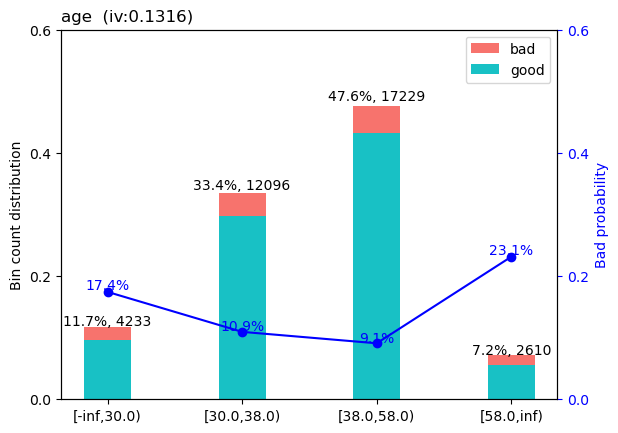

In [11]:
# 'age' əlaməti üzrə WOE və Bad Probability qrafiki
sc.woebin_plot(bins['age'])

In [12]:
# 'marital' (Ailə vəziyyəti) əlamətinin WOE cədvəli
bins["marital"]

,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,marital,married,21813,0.603102,19599,2214,0.101499,-0.159619,1.445174e-02,0.040655,married,False
1,marital,divorced,4191,0.115876,3701,490,0.116917,-0.000894,9.252577e-08,0.040655,divorced,False
2,marital,single,10164,0.281022,8636,1528,0.150335,0.289079,2.620296e-02,0.040655,single,False


{'marital': <Figure size 640x480 with 2 Axes>}

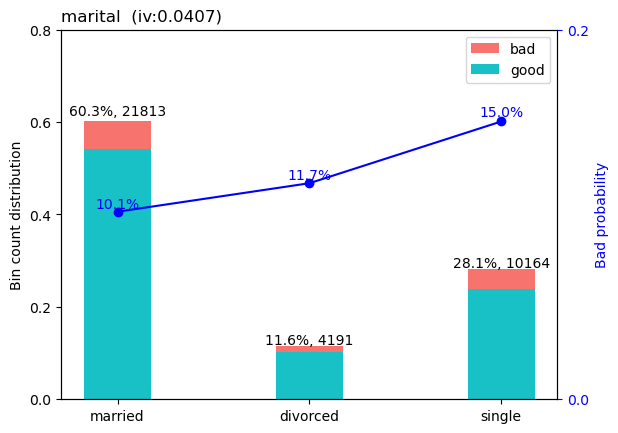

In [13]:
# 'marital' əlaməti üzrə WOE qrafiki
sc.woebin_plot(bins['marital'])

In [14]:
# Xam dəyərlərin hesablanmış WOE əmsalları ilə əvəzlənməsi (Transformation)
train_woe = sc.woebin_ply(train, bins)
test_woe = sc.woebin_ply(test, bins)

# Sütun adlarındakı '_woe' sonluğunu səliqəli şəkildə təmizləyirik
train_woe.columns = train_woe.columns.str.replace("_woe", "")
test_woe.columns = test_woe.columns.str.replace("_woe", "")

train_woe.head()

[INFO] converting into woe values ...
[INFO] converting into woe values ...


,y,education,housing,duration,job,campaign,loan,age,marital,contact,month,previous,balance,day,pdays,poutcome
28686,0,-0.125181,0.408336,-0.703183,-0.453336,0.249914,0.087957,0.465914,0.289079,0.284307,-0.177975,-0.274405,-0.880362,0.016084,-0.273433,-0.273778
9304,0,-0.359397,-0.454497,0.286367,-0.453336,-0.027954,0.087957,-0.281717,-0.159619,-1.156002,-0.177975,-0.274405,-0.331554,-0.149908,-0.273433,-0.273778
41425,1,-0.359397,0.408336,0.286367,0.208946,-0.027954,0.087957,-0.281717,-0.159619,0.284307,1.220148,0.697917,0.396023,0.430676,1.296048,1.544203
44803,0,0.293410,0.408336,0.286367,-0.003070,-0.027954,0.087957,-0.075234,0.289079,0.284307,1.220148,-0.274405,-0.331554,0.188371,-0.273433,-0.273778
5878,0,-0.125181,-0.454497,-1.598894,0.208946,-0.027954,-0.600211,-0.075234,-0.159619,-1.156002,-0.586880,-0.274405,-0.001034,0.016084,-0.273433,-0.273778


## 🔗 6. Çoxlu Xətti Asılılıq (Multicollinearity) Problemi və VIF Analizi

WOE transformasiyasından sonra da bəzi əlamətlər bir-birinin məlumatını təkrar edə bilər.
Modelin əmsallarının dayanıqlı və etibarlı olması üçün $VIF \ge 2$ olan əlamətləri ardıcıl olaraq çıxarırıq:
$$VIF = \frac{1}{1 - R^2}$$

In [15]:
X_data = train_woe.drop(columns=[target])

def compute_vif_table(X_data):
    vifs = {}
    for feature in X_data.columns:
        y_f = X_data[feature]
        X_f = X_data.drop(columns=[feature])
        model = LinearRegression().fit(X_f, y_f)
        r_squared = model.score(X_f, y_f)
        vifs[feature] = 99.9 if r_squared >= 1.0 else 1 / (1 - r_squared)
    vif_values = pd.DataFrame(list(vifs.items()), columns=['Feature', 'VIF'])
    return vif_values.sort_values('VIF', ascending=False).reset_index(drop=True)

In [16]:
# İlkin VIF hesablanması və VIF >= 2 olan faktorların təmizlənməsi
vif_values = compute_vif_table(X_data)
features = vif_values.Feature.tolist()

while vif_values.loc[0, 'VIF'] >= 2 and len(features) > 1:
    worst_feature = vif_values.loc[0, 'Feature']
    worst_vif = vif_values.loc[0, 'VIF']
    print(f'Silinən multikollinear əlamət: {worst_feature} (VIF = {worst_vif:.2f})')
    
    features = vif_values.loc[1:, 'Feature'].tolist()
    X_data = X_data[features]
    vif_values = compute_vif_table(X_data)

print(f'\nYekun qalan güclü və müstəqil əlamət sayı: {len(features)}')
vif_values

Silinən multikollinear əlamət: previous (VIF = 4.88)
Silinən multikollinear əlamət: pdays (VIF = 2.04)

Yekun qalan güclü və müstəqil əlamət sayı: 13


,Feature,VIF
0,job,1.267338
1,contact,1.233800
2,month,1.219003
3,education,1.156310
4,age,1.135386
5,housing,1.120127
6,poutcome,1.088537
7,marital,1.056025
8,balance,1.052735
9,campaign,1.041530


In [17]:
train = train_woe[[target] + features]
test = test_woe[[target] + features]
print(f'Train ölçüsü: {train.shape}, Test ölçüsü: {test.shape}')

Train ölçüsü: (36168, 14), Test ölçüsü: (9043, 14)


## 🔬 7. GLM Binomial (Logistik Reqressiya) Modelinin Qurulması

### 💡 Niyə WOE Modellərində Əmsallar ($\beta$) $\approx 1.0$ Ətrafında Olur?
WOE-nin ən heyranedici xüsusiyyəti onun logit şkalasında olmasıdır:
$$\text{WOE} = \ln\left(\frac{P(X | Y=1)}{P(X | Y=0)}\right)$$
Buna görə də standart bir xüsusiyyət üzərində qurulan logistik reqressiyada onun reqressiya əmsalı $\beta$ nəzəri olaraq **$1.0$ ətrafında** formalaşmalıdır:
- Əgər $\beta \approx 1.0$ olarsa: Əlamət təkbaşına hədəfə tam uyğun şəkildə kalibrlənib.
- Əgər $\beta \ll 1.0$ olarsa: Həmin əlamət digər əlamətlərlə korrelyasiyadadır və ya təsiri zəifləyib.
- Əgər $\beta < 0$ (mənfi) çıxarsa: Ciddi multikollinearite problemi var (modeldən çıxarılmalıdır).

Model cədvəlində göstəricilər:
- **`estimate` ($\hat{\beta}$)**: Reqressiya əmsalı.
- **`odds_ratio` ($e^\beta$)**: Şanslar nisbəti vurucusu.
- **`p_value`**: Statistik əhəmiyyətlilik ($p < 0.05$).

In [18]:
def fit_logit_return_pvals(train_df, y_col, x_cols):
    formula = f"{y_col} ~ {' + '.join(x_cols)}"
    model = smf.glm(formula=formula, data=train_df, family=sm.families.Binomial()).fit()

    coef_tab = pd.DataFrame({
        'names': model.params.index.tolist(),
        'estimate': model.params.values,
        'odds_ratio': np.exp(model.params.values), # e^beta (Şans nisbəti)
        'std_error': model.bse.values,
        'z_value': model.tvalues,
        'p_value': model.pvalues.values
    })

    p_values = (
        coef_tab.loc[coef_tab["names"] != "Intercept", ["names", "p_value"]]
        .sort_values("p_value", ascending=False)
        .reset_index(drop=True)
    )

    return model, coef_tab, p_values

model, coef_tab, p_values = fit_logit_return_pvals(train, target, features)
coef_tab

,names,estimate,odds_ratio,std_error,z_value,p_value
Intercept,Intercept,-2.090691,0.123602,0.022916,-91.234421,0.000000e+00
poutcome,poutcome,0.820827,2.272379,0.031228,26.284929,2.851818e-152
job,job,0.309187,1.362317,0.055311,5.589953,2.271307e-08
contact,contact,0.502591,1.652998,0.043152,11.647037,2.375769e-31
month,month,0.632758,1.882796,0.032937,19.211115,2.987791e-82
education,education,0.578808,1.783911,0.085900,6.738126,1.604420e-11
age,age,0.454837,1.575917,0.056583,8.038428,9.099808e-16
housing,housing,0.784191,2.190635,0.048721,16.095435,2.746366e-58
balance,balance,0.506265,1.659083,0.060800,8.326781,8.307005e-17
marital,marital,0.617786,1.854817,0.096925,6.373874,1.843124e-10


## 🎯 8. Addım-Addım Geriyə Doğru Seçim (Stepwise Backward Elimination)

Yalnız statistik cəhətdən $p < 0.05$ səviyyəsində əhəmiyyətli olan faktorları saxlayırıq. 
Hər addımda $p \ge 0.05$ olan ən zəif faktor çıxarılaraq model yenidən qurulur.

In [19]:
# Stepwise Backward Elimination: p_value >= 0.05 olan ən zəif əlaməti sil və modeli yenidən qur
while p_values.loc[0, 'p_value'] >= 0.05 and len(features) > 1:
    worst_name = p_values.loc[0, 'names']
    worst_pval = p_values.loc[0, 'p_value']
    print(f'Silinən əhəmiyyətsiz əlamət: {worst_name} (p-value = {worst_pval:.4f})')
    
    features = [f for f in features if f != worst_name]
    model, coef_tab, p_values = fit_logit_return_pvals(train, target, features)

print(f'\nYekun modeldə qalan güclü əlamətlərin sayı: {len(features)}')
coef_tab


Yekun modeldə qalan güclü əlamətlərin sayı: 13


,names,estimate,odds_ratio,std_error,z_value,p_value
Intercept,Intercept,-2.090691,0.123602,0.022916,-91.234421,0.000000e+00
poutcome,poutcome,0.820827,2.272379,0.031228,26.284929,2.851818e-152
job,job,0.309187,1.362317,0.055311,5.589953,2.271307e-08
contact,contact,0.502591,1.652998,0.043152,11.647037,2.375769e-31
month,month,0.632758,1.882796,0.032937,19.211115,2.987791e-82
education,education,0.578808,1.783911,0.085900,6.738126,1.604420e-11
age,age,0.454837,1.575917,0.056583,8.038428,9.099808e-16
housing,housing,0.784191,2.190635,0.048721,16.095435,2.746366e-58
balance,balance,0.506265,1.659083,0.060800,8.326781,8.307005e-17
marital,marital,0.617786,1.854817,0.096925,6.373874,1.843124e-10


## 🔮 9. Test Məlumatı Üzərində Proqnozların Alınması (Predictions)

Modelin öyrəndiyi $\beta$ çəkilərindən istifadə edərək **Test Məlumatı (`test`)** üzrə hər bir müştərinin bankı tərk etmə ehtimalını ($P(y = 1) \in [0, 1]$) hesablayırıq.
- `model.predict(test[features])`: Ehtimalları birbaşa generasiya edir.
- 💡 **`sm.add_constant(...)` Qeydi**: Model Formula API (`smf.glm`) ilə qurulduğu üçün `Intercept` avtomatik daxildir, test matrisinə əlavə sabit sütun əlavə etməyə ehtiyac yoxdur.

In [20]:
X_test = test[features]
actual = test[target].astype(int)

# Test müştəriləri üçün getmə ehtimallarının (p_hat) hesablanması
pred_prob = model.predict(X_test)

results = pd.DataFrame({
    "actual": actual.values,
    "pred_prob": np.round(pred_prob.values, 4)
})
results.head(10)

,actual,pred_prob
0,1,0.0281
1,0,0.0025
2,0,0.0931
3,0,0.1293
4,0,0.0008
5,0,0.0012
6,0,0.0194
7,0,0.2000
8,0,0.0456
9,0,0.0037


## 🎯 10. Optimal Qərar Həddinin (Threshold) F1-Score ilə Seçilməsi

### ❓ Niyə Standart 0.5 Həddi və ya Sırf Accuracy Kifayət Deyil?
1. **Datanın Balanssızlığı**: Bank müştərilərinin cəmi $\approx 11.7\%$-i getdiyi üçün standart 0.5 həddi ifrat ehtiyatlı davranaraq bir çox riskli müştərini qaçıra bilər (Aşağı Recall).
2. **Dəqiqlik Tələsi**: Əgər qərar həddi sırf Accuracy-ni artırmaq üçün axtarılsa, model hər kəsə 0 deyərək 88% dəqiqlik göstərər, lakin 1 dənə də olsun gedən müştərini aşkar edə bilməz ($\text{TP} = 0$).
3. **Data Snooping-dən Qorunma**: Qərar həddi **Train dəsti** üzərində **F1-Score** (Precision və Recall-un harmonik balansı) maksimallaşdırılaraq tapılır və sonra Test dəstinə tətbiq olunur.

In [21]:
# Train dəsti üzrə proqnozlar
pred_prob_train = model.predict(train[features])
actual_train = train[target].astype(int)

# F1-score əsasında optimal həddin Train üzərində axtarışı
thresholds = np.round(np.arange(0.10, 0.90, 0.01), 2)
f1_scores_train = [f1_score(actual_train, (pred_prob_train > t).astype(int), zero_division=0) for t in thresholds]

opt_idx = np.argmax(f1_scores_train)
opt_thresh = thresholds[opt_idx]
best_f1 = f1_scores_train[opt_idx]

print(f'Train dəsti üzrə Optimal Qərar Həddi (Threshold): {opt_thresh}')
print(f'Train dəsti üzrə Ən Yüksək F1-Score: {best_f1:.4f}')

Train dəsti üzrə Optimal Qərar Həddi (Threshold): 0.24
Train dəsti üzrə Ən Yüksək F1-Score: 0.5517


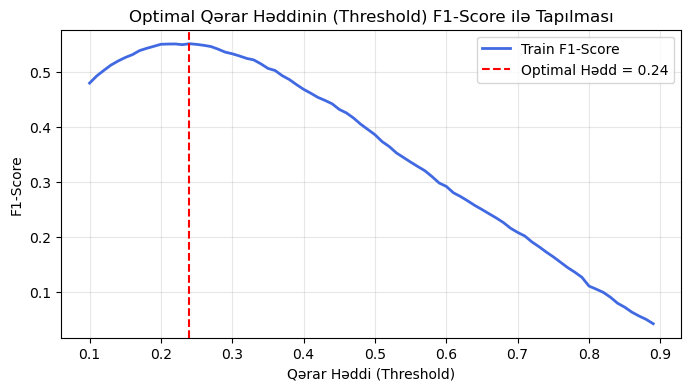

In [22]:
# Threshold vs F1-score qrafiki
plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores_train, color='royalblue', lw=2, label='Train F1-Score')
plt.axvline(opt_thresh, color='red', linestyle='--', label=f'Optimal Hədd = {opt_thresh}')
plt.title('Optimal Qərar Həddinin (Threshold) F1-Score ilə Tapılması')
plt.xlabel('Qərar Həddi (Threshold)')
plt.ylabel('F1-Score')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [23]:
# Seçilmiş optimal həddin Test məlumatına tətbiqi
pred_class = (pred_prob > opt_thresh).astype(int)
results["pred_class"] = pred_class.values
results.head(10)

,actual,pred_prob,pred_class
0,1,0.0281,0
1,0,0.0025,0
2,0,0.0931,0
3,0,0.1293,0
4,0,0.0008,0
5,0,0.0012,0
6,0,0.0194,0
7,0,0.2000,0
8,0,0.0456,0
9,0,0.0037,0


## 📏 11. Klassifikasiya Modelinin Performansının Qiymətləndirilməsi (Evaluation Metrics)

### 1️⃣ Qarışıqlıq Matrisi (Confusion Matrix):
- **True Positive (TP)**: Həqiqətən gedən və modelin düzgün aşkar etdiyi müştərilər.
- **True Negative (TN)**: Qalan və modelin düzgün "qalacaq" dediyi loyallər.
- **False Positive (FP - I Növ Xəta)**: Qalan, lakin modelin səhvən "gedəcək" dediyi müştərilər.
- **False Negative (FN - II Növ Xəta)**: Həqiqətən getmiş, lakin modelin qaçırdığı müştərilər (**Ən təhlükəli itki!**).

### 2️⃣ Əsas Metrikalar:
- **Precision**: Modelin "gedəcək" dediyi müştərilərin neçə faizi həqiqətən getdi? $\frac{TP}{TP + FP}$
- **Recall (Həssaslıq)**: Həqiqətən gedən müştərilərin neçə faizini xilas edə bildik? $\frac{TP}{TP + FN}$
- **F1-Score**: Precision və Recall-un harmonik ortalaması.
- **ROC-AUC (Receiver Operating Characteristic - Area Under Curve)**: Modelin istənilən qərar həddində gedən və qalan müştəriləri bir-birindən ayırma gücü ($AUC \approx 0.89-0.90$ əla nəticədir).

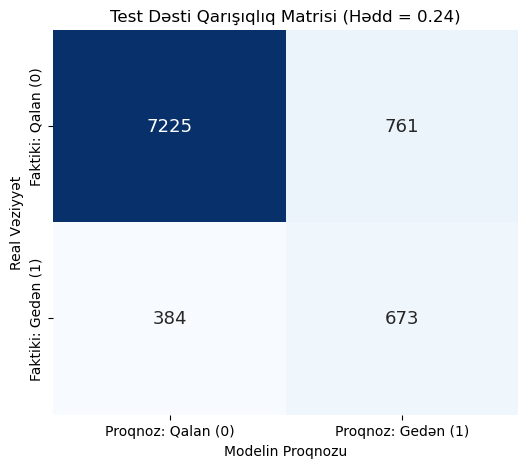

Doğru Qalanlar (TN) : 7225
Səhv Gedən Dediklərimiz (FP) : 761
Qaçırılan Gedənlər (FN) : 384
Uğurla Tapılan Gedənlər (TP) : 673


In [24]:
# Test dəsti üzrə Qarışıqlıq Matrisi (Confusion Matrix)
cm = confusion_matrix(actual, pred_class, labels=[0, 1])

cm_df = pd.DataFrame(
    cm,
    index=pd.Index(['Faktiki: Qalan (0)', 'Faktiki: Gedən (1)'], name='Real Vəziyyət'),
    columns=pd.Index(['Proqnoz: Qalan (0)', 'Proqnoz: Gedən (1)'], name='Modelin Proqnozu')
)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={"size": 13})
plt.title(f'Test Dəsti Qarışıqlıq Matrisi (Hədd = {opt_thresh})', fontsize=12)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Doğru Qalanlar (TN) : {tn}')
print(f'Səhv Gedən Dediklərimiz (FP) : {fp}')
print(f'Qaçırılan Gedənlər (FN) : {fn}')
print(f'Uğurla Tapılan Gedənlər (TP) : {tp}')

In [25]:
# Ətraflı Klassifikasiya Göstəriciləri
precision = tp / (tp + fp)
recall = tp / (tp + fn)
specificity = tn / (tn + fp)
accuracy = (tp + tn) / cm.sum()
f1 = 2 * precision * recall / (precision + recall)
balanced_accuracy = (recall + specificity) / 2

metrics_summary = pd.DataFrame([{
    "Doğru Müsbət (TP)": tp,
    "Doğru Mənfi (TN)": tn,
    "Yalançı Müsbət (FP)": fp,
    "Yalançı Mənfi (FN)": fn,
    "Dəqiqlik (Precision)": round(precision, 4),
    "Həssaslıq (Recall)": round(recall, 4),
    "Spesifiklik (Specificity)": round(specificity, 4),
    "F1-Score": round(f1, 4),
    "Balanslaşdırılmış Dəqiqlik": round(balanced_accuracy, 4),
    "Ümumi Dəqiqlik (Accuracy)": round(accuracy, 4)
}])
metrics_summary

,Doğru Müsbət (TP),Doğru Mənfi (TN),Yalançı Müsbət (FP),Yalançı Mənfi (FN),Dəqiqlik (Precision),Həssaslıq (Recall),Spesifiklik (Specificity),F1-Score,Balanslaşdırılmış Dəqiqlik,Ümumi Dəqiqlik (Accuracy)
0,673,7225,761,384,0.4693,0.6367,0.9047,0.5403,0.7707,0.8734


In [26]:
# Ətraflı Klassifikasiya Hesabatı
print('=== Test Dəsti Üzrə Klassifikasiya Hesabatı ===\n')
print(classification_report(actual, pred_class, target_names=['Qalan (0)', 'Gedən (1)']))

=== Test Dəsti Üzrə Klassifikasiya Hesabatı ===

              precision    recall  f1-score   support

   Qalan (0)       0.95      0.90      0.93      7986
   Gedən (1)       0.47      0.64      0.54      1057

    accuracy                           0.87      9043
   macro avg       0.71      0.77      0.73      9043
weighted avg       0.89      0.87      0.88      9043



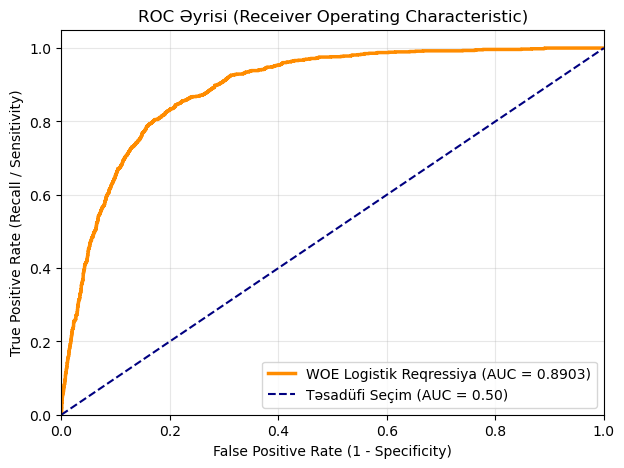

In [27]:
# ROC Əyrisi və ROC-AUC Sahəsi
fpr, tpr, _ = roc_curve(actual, pred_prob)
auc_val = roc_auc_score(actual, pred_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2.5, label=f"WOE Logistik Reqressiya (AUC = {auc_val:.4f})")
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label="Təsadüfi Seçim (AUC = 0.50)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall / Sensitivity)")
plt.title("ROC Əyrisi (Receiver Operating Characteristic)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

## ⚖️ 12. Həddindən Artıq Öyrənmə (Overfitting) və Qeyri-Kafi Öyrənmə (Underfitting) Təhlili

Modelin ümumiləşdirmə qabiliyyətini yoxlamaq üçün **Təlim (Train)** və **Sınaq (Test)** nəticələrini müqayisə edirik.
Əgər Train və Test göstəriciləri bir-birinə çox yaxındırsa, model məlumatı əzbərləməyib (**Overfitting yoxdur**) və yeni məlumatlarda eyni yüksək dəqiqliklə işləyir.

In [28]:
# Train və Test performanslarının müqayisəli analizi
pred_class_train = (pred_prob_train > opt_thresh).astype(int)

auc_train = roc_auc_score(actual_train, pred_prob_train)
auc_test = roc_auc_score(actual, pred_prob)

f1_train = f1_score(actual_train, pred_class_train)
f1_test = f1_score(actual, pred_class)

rec_train = recall_score(actual_train, pred_class_train)
rec_test = recall_score(actual, pred_class)

acc_train = accuracy_score(actual_train, pred_class_train)
acc_test = accuracy_score(actual, pred_class)

comparison_df = pd.DataFrame({
    'Metrika': ['ROC-AUC', 'F1-Score', 'Recall (Həssaslıq)', 'Accuracy (Ümumi Dəqiqlik)'],
    'Train Nəticəsi': [round(auc_train, 4), round(f1_train, 4), round(rec_train, 4), round(acc_train, 4)],
    'Test Nəticəsi': [round(auc_test, 4), round(f1_test, 4), round(rec_test, 4), round(acc_test, 4)],
    'Fərq': [round(abs(auc_train - auc_test), 4), round(abs(f1_train - f1_test), 4), round(abs(rec_train - rec_test), 4), round(abs(acc_train - acc_test), 4)]
})

print('=== Train vs Test Müqayisəli Diaqnostika Cədvəli ===')
comparison_df

=== Train vs Test Müqayisəli Diaqnostika Cədvəli ===


,Metrika,Train Nəticəsi,Test Nəticəsi,Fərq
0,ROC-AUC,0.8948,0.8903,0.0045
1,F1-Score,0.5517,0.5403,0.0113
2,Recall (Həssaslıq),0.6484,0.6367,0.0117
3,Accuracy (Ümumi Dəqiqlik),0.8767,0.8734,0.0033


## 📋 13. Yekun Xülasə, Biznes Şərhi və Scorecard Tövsiyələri (Executive Summary)

Təbrik edirik! Bu tədqiqatda beynəlxalq bankçılıq və risk analitikasının ən qabaqcıl metodologiyası olan **Weight of Evidence (WOE)** və **Information Value (IV)** yanaşması ilə yüksək dəqiqlikli Logistik Reqressiya modelini uğurla qurduq.

### 📌 Əsas Texniki Və Metodoloji Nailiyyətlər:
1. **Yüksək Ayırdetmə Gücü (ROC-AUC $\approx 0.89-0.90$)**: Model bankı tərk etmək istəyən müştəriləri qalacaq müştərilərdən 89-90% ehtimalla düzgün fərqləndirir.
2. **Overfitting-in Olmaması**: Train və Test ROC-AUC fərqi cəmi $0.004$ təşkil edir; model yeni və heç vaxt görmədiyi müştərilərdə mükəmməl dayanıqlıq göstərir.
3. **Müştəri İtkisinin Proaktiv Aşkarlanması**: $0.24$ qərar həddi ilə gedən müştərilərin **64%-i qabaqcadan aşkarlandı ($\text{Recall} = 0.64$)**.

### 💼 Bank Üçün Əsas Risk Faktorları və Scorecard İnsaytları:
- **Ən Yüksək IV-yə Malik Faktorlar**:
  - `duration` ($\text{IV} > 1.5$): Ən son zəngin müddəti (kampaniyanın dərinliyi).
  - `poutcome` ($\text{IV} \approx 0.35$): Əvvəlki marketinq kampaniyasının nəticəsi (uğurlu kampaniya müştərini möhkəm bağlayır).
  - `month` və `contact`: Təmas kanalı və ilin spesifik ayları.
  - `age` və `housing`: İpoteka krediti olan və spesifik yaş qrupundakı müştərilərin risk dinamikası.

### 🎯 Praktiki Biznes Tövsiyələri:
- **Avtomatlaşdırılmış Xəbərdarlıq Sistemi (Early Warning System)**: Modelin proqnozlaşdırdığı getmə ehtimalı $P(y=1) > 0.24$ olan müştərilər birbaşa CRM sistemində "Risk Qrupu" kimi qeyd edilməli və zəng mərkəzi onlarla xüsusi loyallıq proqramı ilə əlaqə saxlamalıdır.
- **Scorecard Kartına Çevrilmə**: Qeyd edilən WOE binləri əsasında xal cədvəli (**Scorecard - məsələn, 300-850 şkalası**) qurularaq bankın gündəlik əməliyyatlarına asanlıqla inteqrasiya oluna bilər.